L’analyse exploratoire orientée business

Pourquoi. L’EDA n’est pas là pour faire de jolis graphiques, mais pour répondre à des questions de décision avant toute modélisation :

Quel est le taux de churn, et à quel point la cible est-elle déséquilibrée ?
Qui part ? Quels profils (plaintes, statut, plan tarifaire, usage) ont un taux de churn très différent de la moyenne ?
Les variables d’usage sont-elles redondantes entre elles (multicolinéarité) ?
Y a-t-il des pièges dans les données (doublons, valeurs aberrantes, variables suspectes) ?

Chaque graphique doit se terminer par une phrase en langage business : « les clients qui se plaignent résilient X fois plus souvent ». 

Imports et chargement des données 

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from churn.data import load_raw

sns.set_theme(style="whitegrid")
df = load_raw()
print(df.shape)
df.head()

300 fully duplicated rows found (kept, to be reviewed in EDA)


(3150, 14)


,call_failure,complains,subscription_length,charge_amount,seconds_of_use,frequency_of_use,frequency_of_sms,distinct_called_numbers,age_group,tariff_plan,status,age,customer_value,churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


taux de churn et déséquilibre

In [2]:
churn_rate = df["churn"].mean()
print(f"Churn rate in the sample: {churn_rate:.2%} ({df['churn'].sum()} / {len(df)})")
print(f"Baseline accuracy of 'nobody churns': {1 - churn_rate:.2%}")

Churn rate in the sample: 15.71% (495 / 3150)
Baseline accuracy of 'nobody churns': 84.29%


Lignes dupliquées 

In [3]:
n_dup = df.duplicated().sum()
print(f"Fully duplicated rows: {n_dup} ({n_dup / len(df):.2%})")

Fully duplicated rows: 300 (9.52%)


Comprendre les doublons 

In [16]:
feature_cols = [c for c in df.columns if c != "churn"]
dups = df[df.duplicated(keep="first")]
unique_rows = df.drop_duplicates()

print("Rows involved in a duplicate group:", df.duplicated(keep=False).sum())
print("Rows after dropping duplicates     :", len(unique_rows))
print(f"Churn rate (duplicates only)       : {dups['churn'].mean():.1%}")
print(f"Churn rate (deduplicated dataset)  : {unique_rows['churn'].mean():.1%}")
print(f"Duplicates with customer_value = 0 : {(dups['customer_value'] == 0).mean():.1%}")
print(f"Duplicates with seconds_of_use = 0 : {(dups['seconds_of_use'] == 0).mean():.1%}")

# Identical features but DIFFERENT churn label = contradictory rows
conflicts = df.groupby(feature_cols)["churn"].nunique()
print("Feature profiles with contradictory churn labels:", (conflicts > 1).sum())

print(dups.describe().round(1).T[["mean", "min", "50%", "max"]])

Rows involved in a duplicate group: 465
Rows after dropping duplicates     : 2850
Churn rate (duplicates only)       : 16.3%
Churn rate (deduplicated dataset)  : 15.6%
Duplicates with customer_value = 0 : 15.7%
Duplicates with seconds_of_use = 0 : 15.7%
Feature profiles with contradictory churn labels: 14
                           mean   min     50%      max
call_failure                6.0   0.0     5.0     30.0
complains                   0.0   0.0     0.0      1.0
subscription_length        33.4   7.0    36.0     41.0
charge_amount               0.6   0.0     0.0      9.0
seconds_of_use           3885.5   0.0  2619.0  16380.0
frequency_of_use           59.7   0.0    45.5    244.0
frequency_of_sms           67.3   0.0    12.0    490.0
distinct_called_numbers    20.1   0.0    18.0     82.0
age_group                   2.7   1.0     3.0      5.0
tariff_plan                 1.1   1.0     1.0      2.0
status                      1.3   1.0     1.0      2.0
age                        30.2  

In [17]:
key = df[feature_cols].astype(str).agg("|".join, axis=1)
df_k = df.assign(profile=key)
g = df_k.groupby("profile")["churn"].agg(rows="size", churners="sum")
conflict_profiles = g[(g.churners > 0) & (g.churners < g.rows)].index

print("Group size distribution (duplicated groups only):")
print(g[g.rows > 1]["rows"].value_counts().sort_index())
print()
print(df_k[df_k.profile.isin(conflict_profiles)]
      .sort_values("profile")[["profile", "churn"]].head(12))
print()
print("Median seconds_of_use, contradictory profiles:",
      df_k[df_k.profile.isin(conflict_profiles)]["seconds_of_use"].median())

Group size distribution (duplicated groups only):
rows
2      37
3     117
4       2
5       2
6       2
10      1
11      1
Name: count, dtype: int64

                                   profile  churn
41    0|0|26|0|825|10|21|3|4|1|2|45|73.375      1
1041  0|0|26|0|825|10|21|3|4|1|2|45|73.375      0
991   0|0|26|0|825|10|21|3|4|1|2|45|73.375      0
1828         0|0|29|0|0|0|0|0|2|1|2|25|0.0      1
1366         0|0|29|0|0|0|0|0|2|1|2|25|0.0      0
1368         0|0|29|0|0|0|0|0|2|1|2|25|0.0      1
1818         0|0|30|0|0|0|0|0|2|1|2|25|0.0      1
1278         0|0|30|0|0|0|0|0|2|1|2|25|0.0      1
1367         0|0|30|0|0|0|0|0|2|1|2|25|0.0      0
1351         0|0|31|0|0|0|0|0|2|1|2|25|0.0      0
1268         0|0|31|0|0|0|0|0|2|1|2|25|0.0      1
318          0|0|31|0|0|0|0|0|2|1|2|25|0.0      1

Median seconds_of_use, contradictory profiles: 0.0


taux de churn par variable catégorielle

In [4]:
cat_cols = ["complains", "status", "tariff_plan", "age_group", "charge_amount"]

for col in cat_cols:
    t = (
        df.groupby(col)["churn"]
        .agg(customers="size", churners="sum", churn_rate="mean")
        .round(3)
    )
    print(f"\n--- {col} ---")
    print(t)


--- complains ---
           customers  churners  churn_rate
complains                                 
0               2909       295       0.101
1                241       200       0.830

--- status ---
        customers  churners  churn_rate
status                                 
1            2368       125       0.053
2             782       370       0.473

--- tariff_plan ---
             customers  churners  churn_rate
tariff_plan                                 
1                 2905       489       0.168
2                  245         6       0.024

--- age_group ---
           customers  churners  churn_rate
age_group                                 
1                123         0       0.000
2               1037       184       0.177
3               1425       230       0.161
4                395        79       0.200
5                170         2       0.012

--- charge_amount ---
               customers  churners  churn_rate
charge_amount                             

graphique du churn par segment

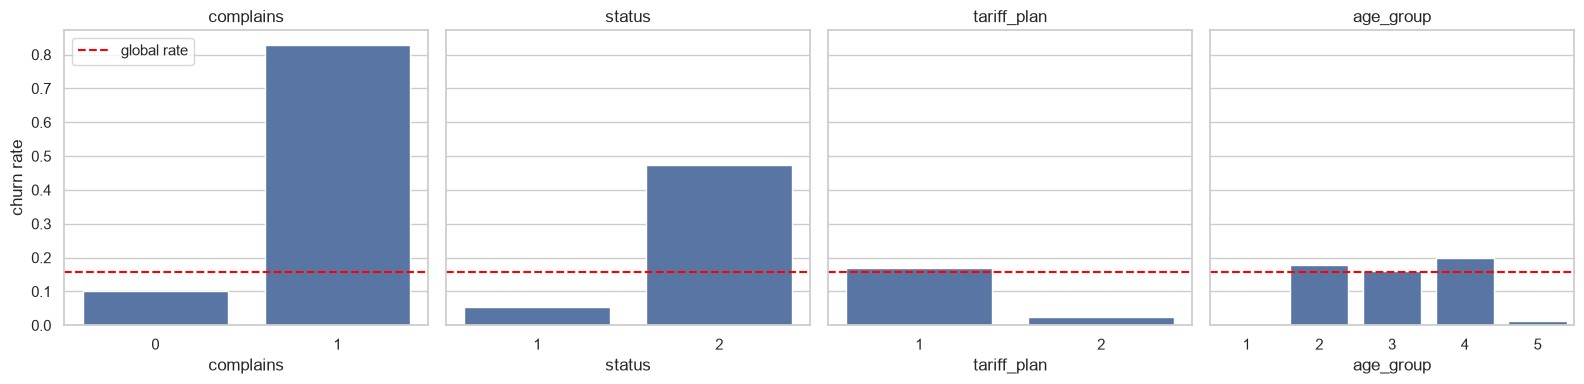

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, col in zip(axes, ["complains", "status", "tariff_plan", "age_group"]):
    rates = df.groupby(col)["churn"].mean()
    sns.barplot(x=rates.index, y=rates.values, ax=ax, color="#4C72B0")
    ax.axhline(churn_rate, color="red", linestyle="--", label="global rate")
    ax.set_title(col)
    ax.set_ylabel("churn rate")
axes[0].legend()
plt.tight_layout()
plt.savefig("../reports/figures/churn_rate_by_segment.png", dpi=150)
plt.show()

variables numériques selon le churn

In [ ]:
num_cols = ["call_failure", "subscription_length", "seconds_of_use",
            "frequency_of_use", "frequency_of_sms", "distinct_called_numbers",
            "customer_value"] # "age"

print(df.groupby("churn")[num_cols].median().round(1).T)

churn                         0       1
call_failure                6.0     5.0
subscription_length        35.0    35.0
seconds_of_use           3530.0  1182.0
frequency_of_use           63.0    25.0
frequency_of_sms           25.0     9.0
distinct_called_numbers    23.0    10.0
customer_value            268.1    96.8
age                        30.0    30.0


corrélations

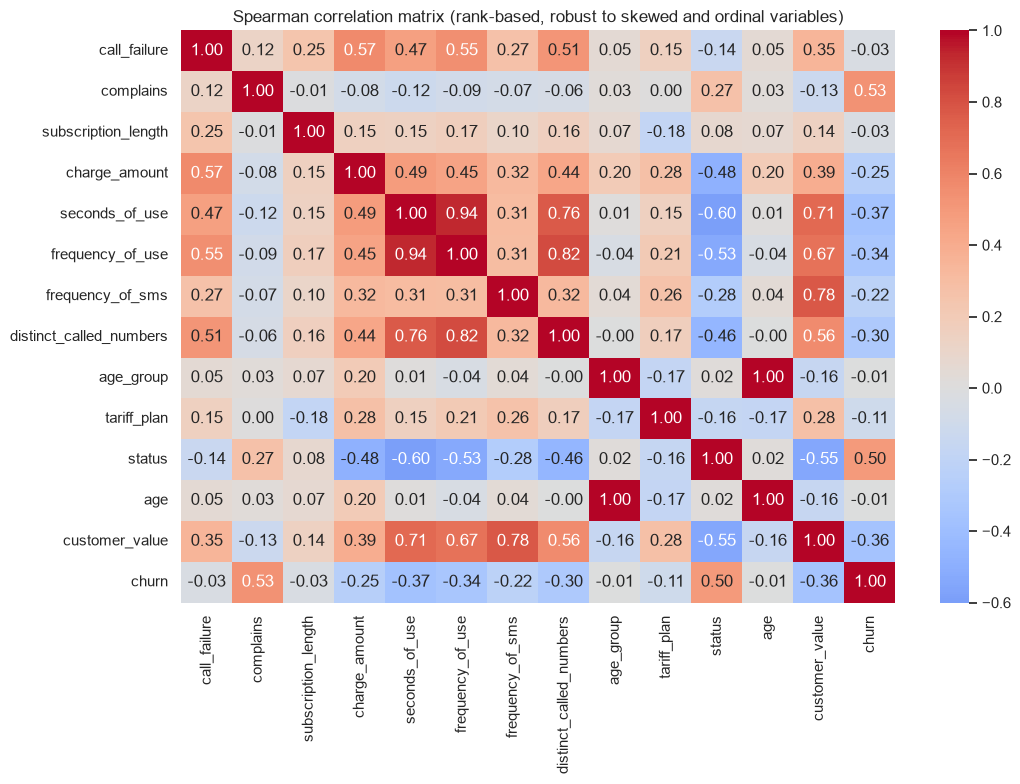

In [14]:
plt.figure(figsize=(11, 8))
sns.heatmap(df.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation matrix (rank-based, robust to skewed and ordinal variables)")
plt.tight_layout()
plt.savefig("../reports/figures/correlation_matrix.png", dpi=150)
plt.show()

In [8]:
print((df[num_cols] == 0).mean().round(3))

call_failure               0.223
subscription_length        0.000
seconds_of_use             0.049
frequency_of_use           0.049
frequency_of_sms           0.191
distinct_called_numbers    0.049
customer_value             0.042
age                        0.000
dtype: float64


Analyse de la distribution 

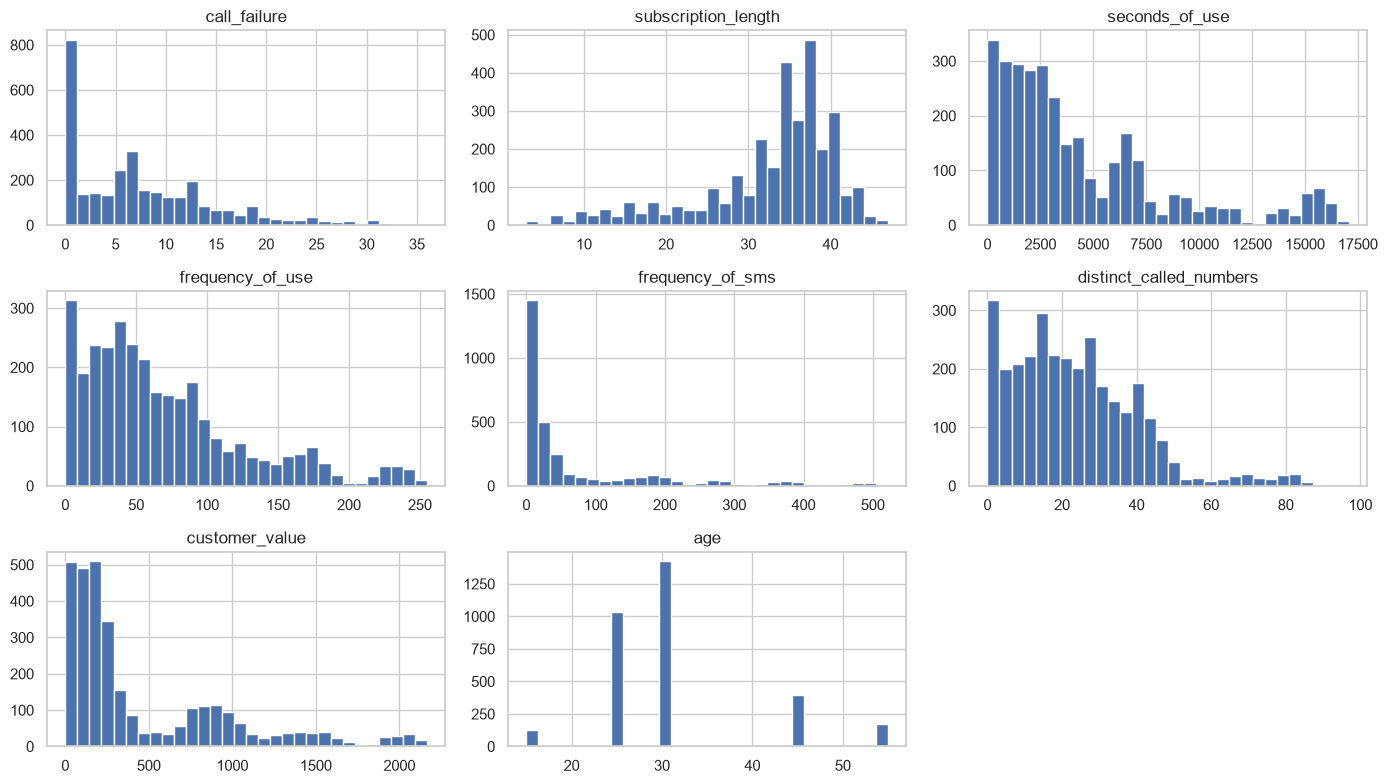

call_failure               1.09
subscription_length       -1.30
seconds_of_use             1.32
frequency_of_use           1.14
frequency_of_sms           1.97
distinct_called_numbers    1.03
customer_value             1.43
age                        1.25
dtype: float64


In [9]:
df[num_cols].hist(bins=30, figsize=(14, 8))
plt.tight_layout()
plt.savefig("../reports/figures/distributions.png", dpi=150)
plt.show()
print(df[num_cols].skew().round(2))

In [19]:
zero_usage = (df.seconds_of_use == 0) & (df.frequency_of_use == 0)
print("Zero-usage customers:", zero_usage.sum())
print(df[zero_usage].groupby("status")["churn"].agg(["size", "mean"]).round(3))
print("Zero usage but customer_value > 0:", (zero_usage & (df.customer_value > 0)).sum())

active = df[df.status == 1]
print("Active customers:", len(active), "| churners among them:", active.churn.sum(),
      f"| rate: {active.churn.mean():.1%}")

Zero-usage customers: 154
        size   mean
status             
1         33  0.182
2        121  0.620
Zero usage but customer_value > 0: 22
Active customers: 2368 | churners among them: 125 | rate: 5.3%


outliers (règle de l’IQR) et boxplots selon le churn

call_failure               0.015
subscription_length        0.090
seconds_of_use             0.063
frequency_of_use           0.041
frequency_of_sms           0.117
distinct_called_numbers    0.024
customer_value             0.037
age                        0.218
dtype: float64


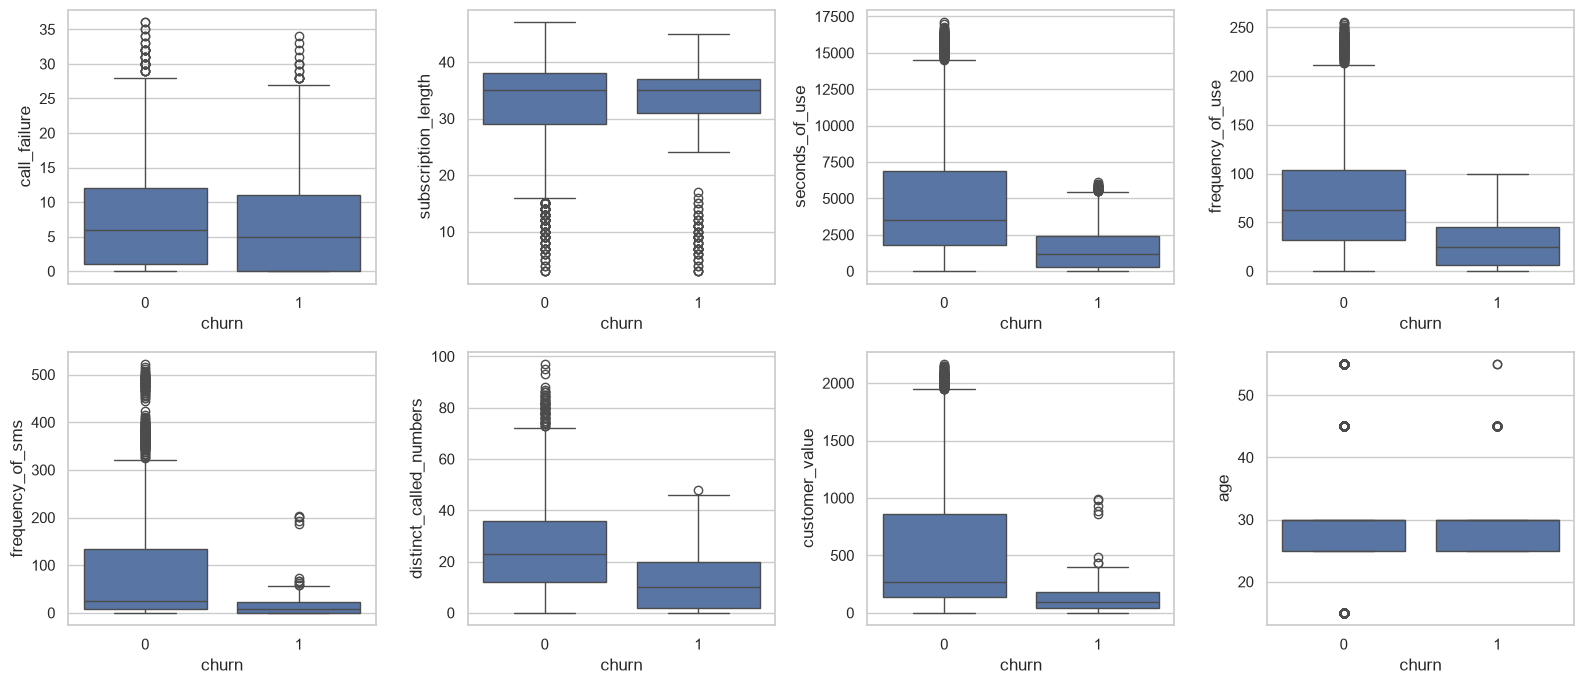

In [10]:
def iqr_outlier_share(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).mean()

print(df[num_cols].apply(iqr_outlier_share).round(3))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), num_cols):
    sns.boxplot(data=df, x="churn", y=col, ax=ax)
plt.tight_layout()
plt.savefig("../reports/figures/boxplots_by_churn.png", dpi=150)
plt.show()

cohérence entre variables

In [18]:
print("calls = 0 but seconds > 0   :", ((df.frequency_of_use == 0) & (df.seconds_of_use > 0)).sum())
print("seconds = 0 but calls > 0   :", ((df.seconds_of_use == 0) & (df.frequency_of_use > 0)).sum())
print(df.groupby("age_group")["age"].agg(["min", "max", "count"]))

calls = 0 but seconds > 0   : 0
seconds = 0 but calls > 0   : 0
           min  max  count
age_group                 
1           15   15    123
2           25   25   1037
3           30   30   1425
4           45   45    395
5           55   55    170


valeur à risque

In [11]:
value = df.groupby("churn")["customer_value"].agg(["count", "sum", "mean", "median"]).round(1)
value["share_of_total_value"] = (value["sum"] / value["sum"].sum()).round(3)
print(value)

       count        sum   mean  median  share_of_total_value
churn                                                       
0       2655  1421783.0  535.5   268.1                 0.958
1        495    61781.6  124.8    96.8                 0.042


interaction plainte × statut

In [12]:
print(df.pivot_table(index="complains", columns="status", values="churn",
                     aggfunc=["mean", "size"]).round(3))

            mean         size     
status         1      2     1    2
complains                         
0          0.029  0.367  2285  624
1          0.711  0.892    83  158


corrélation de Spearman avec le churn

In [13]:
print(df.corr(method="spearman")["churn"].drop("churn").sort_values().round(3))

seconds_of_use            -0.367
customer_value            -0.361
frequency_of_use          -0.343
distinct_called_numbers   -0.302
charge_amount             -0.251
frequency_of_sms          -0.224
tariff_plan               -0.106
subscription_length       -0.035
call_failure              -0.032
age_group                 -0.005
age                       -0.005
status                     0.499
complains                  0.532
Name: churn, dtype: float64


associations avec le churn, une méthode par type

In [15]:
from scipy.stats import chi2_contingency, mannwhitneyu
import numpy as np

# Categorical / ordinal vs churn: chi-squared + Cramer's V
cat_cols = ["complains", "status", "tariff_plan", "age_group", "charge_amount"]
rows = []
for col in cat_cols:
    table = pd.crosstab(df[col], df["churn"])
    chi2, p, _, _ = chi2_contingency(table)
    v = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))
    rows.append({"variable": col, "cramers_v": round(v, 3), "p_value": p})
print(pd.DataFrame(rows).sort_values("cramers_v", ascending=False).to_string(index=False))

# Quantitative vs churn: Mann-Whitney U test
rows = []
for col in num_cols:
    u, p = mannwhitneyu(df.loc[df.churn == 1, col], df.loc[df.churn == 0, col])
    auc = u / (df.churn.sum() * (df.churn == 0).sum())
    rows.append({"variable": col, "auc_univariate": round(auc, 3), "p_value": p})
print(pd.DataFrame(rows).sort_values("auc_univariate").to_string(index=False))

     variable  cramers_v       p_value
    complains      0.530 9.756043e-195
       status      0.498 6.918765e-172
charge_amount      0.255  2.046805e-38
    age_group      0.137  4.807068e-12
  tariff_plan      0.104  4.928098e-09
               variable  auc_univariate      p_value
         seconds_of_use           0.209 3.792258e-94
         customer_value           0.214 2.992857e-91
       frequency_of_use           0.228 8.661908e-83
distinct_called_numbers           0.261 2.416774e-64
       frequency_of_sms           0.323 3.614691e-36
    subscription_length           0.473 5.252314e-02
           call_failure           0.475 7.288924e-02
                    age           0.496 7.743611e-01


## EDA conclusions

**Data quality**
- 3,150 customers, 14 columns, no missing values. Sample churn rate: 15.7% (baseline accuracy of "nobody churns": 84.3%).
- 300 rows are exact duplicates (9.5%). Duplicate groups are mostly triplets, and 14 profiles carry contradictory churn labels (mostly customers with zero usage). They are most likely distinct customers who look identical, so we **keep them** and use grouped splits to avoid train/test leakage.
- `age` takes only 5 values and maps one-to-one onto `age_group`: it is a recoded band, not a true age. It is dropped.
- `charge_amount` ranges from 0 to 10 (the data dictionary says 0 to 9).

**Who churns**
- Complaints: 83% churn vs 10% (Cramér's V = 0.53). Status inactive: 47% vs 5% (V = 0.50). Both are strong but probably partly *consequences* of leaving rather than causes.
- 75% of churners are already inactive; only 40% have complained. The 125 churners still active are the ones a campaign can realistically save.
- Usage is the main behavioural signal: churners use roughly 3x less (calls, seconds, SMS, distinct numbers). Univariate discriminating power (1 - AUC) is about 0.68 to 0.79.
- Contract customers almost never churn (2.4%). Churn drops sharply with `charge_amount` (24% at level 0, 7% at level 1, under 4% from level 3). `age_group` is not monotonic (group 4 has the highest rate, groups 1 and 5 almost none).
- `subscription_length` and `call_failure` do not separate churners alone. Any conditional effect will be assessed in the model.

**Business angle**
- Churners are 15.7% of customers but only 4.2% of total customer value. Retention offers must be cheap to be profitable. The definition of `customer_value` is undocumented, so cost assumptions will be explicit in the config.

**Decisions for modelling**
1. Drop `age`; encode `age_group` as categorical; group `charge_amount` into 0 / 1 / 2 / 3+; recode `status` and `tariff_plan` as clear 0/1 flags.
2. Keep duplicates and outliers; use grouped stratified CV; log or robust scaling for linear models.
3. Strongly correlated usage block (up to 0.94): regularise linear models.
4. Evaluate with PR-AUC and recall at top-k, not accuracy; report the active-only subgroup separately.
5. Compare models with and without `status` / `complains` to measure early-warning ability.